# Graph Mining

Struktur tautan web (*web hyperlink structure*) dimodelkan secara matematis
menggunakan teori graf (*graph theory*). Dalam penambangan struktur web
(*web structure mining*), setiap dokumen atau halaman web diposisikan sebagai
**simpul (*vertex* / *node*)**, sedangkan tautan hiperteks (*hyperlink*) antarhalaman
diposisikan sebagai **sisi (*edge* / *link*)**.

Terdapat dua paradigma utama representasi graf:
1. **Graf Tidak Berarah (*Undirected Graph*)**: Sisi tidak memiliki orientasi arah
   sehingga relasi antara simpul $u$ dan simpul $v$ bersifat simetris dua arah
   ($(u, v) \equiv (v, u)$). Pada web mining, model ini mencerminkan relasi kemitraan
   atau keterhubungan timbal balik.
2. **Graf Berarah (*Directed Graph* / *DiGraph*)**: Sisi memiliki orientasi panah
   asimetris ($(u, v) \neq (v, u)$), di mana tautan keluar dari $u$ menuju $v$.
   Ini adalah representasi alami struktur *hyperlink* web (fondasi PageRank dan HITS).

Notebook ini menyimulasikan graf 5 simpul ($A, B, C, D, E$) untuk menghitung
secara komparatif:
1. Derajat simpul (*degree*, in-degree, out-degree, total degree).
2. Distribusi derajat vertex ($P(k)$).
3. Rata-rata derajat ($\langle k \rangle$).
4. Kepadatan graf (*graph density*).
5. Matriks ketetanggaan (*adjacency matrix*).
6. Koefisien kluster lokal ($C_i$) dan global ($\langle C \rangle$).
7. Diameter graf dan rata-rata panjang lintasan terpendek (*average shortest path length*).
8. Karakterisasi struktural graf (*graph characterization*).

## Undirected Graph

Graf tidak berarah dibangun dengan 5 simpul ($A, B, C, D, E$) dan 6 sisi simetris:
$(A, B), (A, C), (A, D), (B, C), (B, E), (C, D)$.

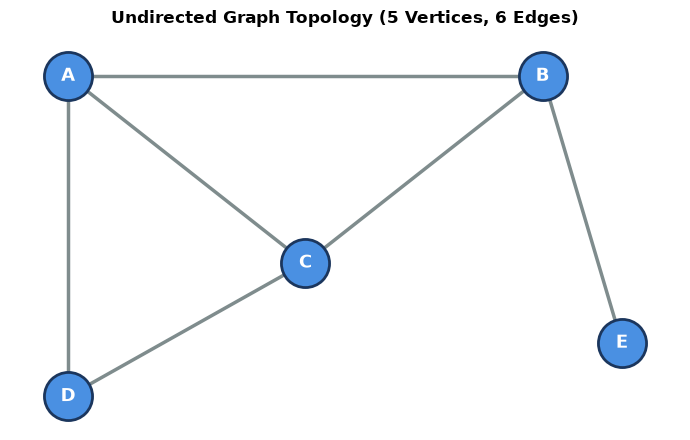

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

# Inisialisasi graf tidak berarah
G_undir = nx.Graph()
vertices = ["A", "B", "C", "D", "E"]
G_undir.add_nodes_from(vertices)

edges_undir = [("A", "B"), ("A", "C"), ("A", "D"), ("B", "C"), ("B", "E"), ("C", "D")]
G_undir.add_edges_from(edges_undir)

# Posisi simpul konsisten untuk visualisasi
pos = {
    "A": (0.2, 0.7),
    "B": (0.8, 0.7),
    "C": (0.5, 0.35),
    "D": (0.2, 0.1),
    "E": (0.9, 0.2),
}

plt.figure(figsize=(7, 4.5), dpi=100)
nx.draw_networkx_nodes(
    G_undir,
    pos,
    node_color="#4A90E2",
    node_size=1200,
    edgecolors="#1B365D",
    linewidths=2,
)
nx.draw_networkx_edges(G_undir, pos, width=2.5, edge_color="#7F8C8D")
nx.draw_networkx_labels(
    G_undir, pos, font_size=13, font_weight="bold", font_color="white"
)

plt.title(
    "Undirected Graph Topology (5 Vertices, 6 Edges)",
    fontsize=12,
    pad=14,
    fontweight="bold",
)
plt.axis("off")
plt.tight_layout()
plt.show()

Visualisasi memperlihatkan topologi graf tidak berarah: simpul $A$, $B$, dan $C$
membentuk segitiga sentral yang saling terhubung erat (*dense core*). Simpul $D$ terhubung
ke simpul inti $A$ dan $C$, sedangkan simpul $E$ berada di periferal jaringan dan hanya
terhubung secara tunggal ke simpul $B$.

## Undirected Adjacency

**Matriks Ketetanggaan (*Adjacency Matrix*)** adalah representasi matriks biner
$A \in \{0, 1\}^{N \times N}$ berukuran $5 \times 5$, di mana elemen baris $i$ dan
kolom $j$ bernilai:
$$A_{ij} = \begin{cases} 1 & \text{jika terdapat sisi antara simpul } i \text{ dan } j \\ 0 & \text{lainnya} \end{cases}$$

In [2]:
adj_undir_matrix = nx.to_numpy_array(G_undir, nodelist=vertices, dtype=int)
adj_undir_df = pd.DataFrame(adj_undir_matrix, index=vertices, columns=vertices)
adj_undir_df.index.name = "Simpul"
adj_undir_df

,A,B,C,D,E
Simpul,,,,,
A,0,1,1,1,0
B,1,0,1,0,1
C,1,1,0,1,0
D,1,0,1,0,0
E,0,1,0,0,0


Matriks ketetanggaan graf tidak berarah bersifat simetris sempurna ($A = A^T$),
di mana $A_{ij} = A_{ji}$. Diagonal utama bernilai nol karena graf tidak memiliki
gelung (*self-loop*). Jumlah nilai 1 pada setiap baris sama dengan derajat simpul
tersebut.

## Undirected Metrics

Dua metrik struktural fundamental tingkat simpul:
1. **Derajat Simpul (*Degree*, $k_i$)**: Jumlah tetangga langsung yang terhubung ke simpul $i$.
2. **Koefisien Kluster (*Clustering Coefficient*, $C_i$)**: Ukuran kerapatan relasi antartetangga:
   $$C_i = \frac{2 e_i}{k_i (k_i - 1)}$$
   di mana $e_i$ adalah jumlah sisi nyata yang menghubungkan antartetangga simpul $i$.

In [3]:
degree_dict = dict(G_undir.degree())
clustering_dict = nx.clustering(G_undir)

metrics_undir = []
for node in vertices:
    neighbors = list(G_undir.neighbors(node))
    k = degree_dict[node]
    subgraph = G_undir.subgraph(neighbors)
    e_i = subgraph.number_of_edges()
    max_e = k * (k - 1) // 2 if k >= 2 else 0
    c_i = clustering_dict[node]
    metrics_undir.append(
        {
            "Simpul": node,
            "Tetangga Langsung": ", ".join(sorted(neighbors)),
            "Degree (k_i)": k,
            "Sisi Antartetangga (e_i)": e_i,
            "Maks Sisi Tetangga": max_e,
            "Clustering Coefficient": round(c_i, 4),
        }
    )

undir_metrics_df = pd.DataFrame(metrics_undir).set_index("Simpul")
undir_metrics_df

,Tetangga Langsung,Degree (k_i),Sisi Antartetangga (e_i),Maks Sisi Tetangga,Clustering Coefficient
Simpul,,,,,
A,"B, C, D",3,2,3,0.6667
B,"A, C, E",3,1,3,0.3333
C,"A, B, D",3,2,3,0.6667
D,"A, C",2,1,1,1.0000
E,B,1,0,0,0.0000


Hasil perhitungan memperlihatkan karakteristik lokal setiap simpul:
- **Simpul $A, B, C$** memiliki derajat tertinggi ($k=3$) sebagai hub konektivitas.
- **Simpul $D$** memiliki *Clustering Coefficient* maksimal (**1,0000**) karena kedua tetangganya ($A$ dan $C$) saling terhubung membentuk segitiga tertutup ($e_D = 1$ dari maks 1).
- **Simpul $E$** memiliki derajat 1 ($k=1$), sehingga secara matematis tidak memiliki pasangan tetangga ($C_E = 0,0000$).

## Undirected Distribution

**Distribusi Derajat (*Degree Distribution*, $P(k)$)** merepresentasikan probabilitas
atau frekuensi kemunculan simpul dengan derajat $k$ tertentu di dalam jaringan:
$$P(k) = \frac{N_k}{N}$$

In [4]:
deg_series = pd.Series(degree_dict)
deg_counts = deg_series.value_counts().sort_index()

dist_undir_list = []
total_nodes = len(vertices)
for k, count in deg_counts.items():
    nodes_with_k = [n for n, deg in degree_dict.items() if deg == k]
    p_k = count / total_nodes
    dist_undir_list.append(
        {
            "Derajat (k)": k,
            "Jumlah Simpul (N_k)": count,
            "Probabilitas P(k)": round(p_k, 4),
            "Persentase": f"{p_k * 100:.1f}%",
            "Daftar Simpul": ", ".join(nodes_with_k),
        }
    )

dist_undir_df = pd.DataFrame(dist_undir_list).set_index("Derajat (k)")
dist_undir_df

,Jumlah Simpul (N_k),Probabilitas P(k),Persentase,Daftar Simpul
Derajat (k),,,,
1,1,0.2,20.0%,E
2,1,0.2,20.0%,D
3,3,0.6,60.0%,"A, B, C"


Tabel distribusi memperlihatkan mayoritas simpul (60% atau 3 simpul) berpusat pada
derajat $k=3$. Simpul dengan derajat rendah ($k=1$ dan $k=2$) masing-masing mencakup
20% dari keseluruhan jaringan.

## Undirected Macro

Metrik makro merangkum karakteristik global jaringan:
1. **Rata-rata Derajat (*Average Degree*, $\langle k \rangle$)**: $\langle k \rangle = \frac{2E}{N}$.
2. **Kepadatan Graf (*Graph Density*, $\rho$)**: Rasio sisi nyata terhadap sisi maksimal: $\rho = \frac{2E}{N(N-1)}$.
3. **Rata-rata Koefisien Kluster ($\langle C \rangle$)**: Rata-rata kerapatan kluster seluruh simpul: $\langle C \rangle = \frac{1}{N} \sum C_i$.
4. **Diameter Graf**: Jarak terpendek terpanjang antar dua simpul manapun: $\text{diam}(G) = \max d(i, j)$.
5. **Rata-rata Panjang Lintasan Terpendek ($L$)**: Jarak rata-rata antarseluruh pasangan simpul:
   $$L = \frac{1}{N(N-1)} \sum_{i \neq j} d(i, j)$$

In [5]:
avg_deg_undir = sum(degree_dict.values()) / len(vertices)
density_undir = nx.density(G_undir)
avg_clust_undir = nx.average_clustering(G_undir)
diameter_undir = nx.diameter(G_undir)
avg_path_undir = nx.average_shortest_path_length(G_undir)

macro_undir_df = pd.DataFrame(
    [
        {
            "Metrik Makro": "Jumlah Simpul (N)",
            "Nilai": len(vertices),
            "Keterangan": "Total vertex jaringan",
        },
        {
            "Metrik Makro": "Jumlah Sisi (E)",
            "Nilai": G_undir.number_of_edges(),
            "Keterangan": "Total sisi simetris",
        },
        {
            "Metrik Makro": "Rata-rata Derajat (<k>)",
            "Nilai": round(avg_deg_undir, 4),
            "Keterangan": "Rata-rata relasi per simpul",
        },
        {
            "Metrik Makro": "Kepadatan Graf (Density)",
            "Nilai": round(density_undir, 4),
            "Keterangan": "6 sisi dari 10 sisi maksimal (60%)",
        },
        {
            "Metrik Makro": "Rata-rata Koefisien Kluster (<C>)",
            "Nilai": round(avg_clust_undir, 4),
            "Keterangan": "Kerapatan segitiga global jaringan",
        },
        {
            "Metrik Makro": "Diameter Graf",
            "Nilai": diameter_undir,
            "Keterangan": "Jarak terjauh terpendek (simpul D ke E)",
        },
        {
            "Metrik Makro": "Rata-rata Lintasan Terpendek",
            "Nilai": round(avg_path_undir, 4),
            "Keterangan": "Jarak rata-rata antarpasangan simpul",
        },
    ]
).set_index("Metrik Makro")
macro_undir_df

,Nilai,Keterangan
Metrik Makro,,
Jumlah Simpul (N),5.0000,Total vertex jaringan
Jumlah Sisi (E),6.0000,Total sisi simetris
Rata-rata Derajat (<k>),2.4000,Rata-rata relasi per simpul
Kepadatan Graf (Density),0.6000,6 sisi dari 10 sisi maksimal (60%)
Rata-rata Koefisien Kluster (<C>),0.5333,Kerapatan segitiga global jaringan
Diameter Graf,3.0000,Jarak terjauh terpendek (simpul D ke E)
Rata-rata Lintasan Terpendek,1.5000,Jarak rata-rata antarpasangan simpul


Kepadatan graf tidak berarah bernilai **0,6000**, mengindikasikan 60% dari kapasitas
koneksi maksimum telah terisi. Rata-rata lintasan terpendek adalah **1,5000 langkah** dengan
**diameter 3 langkah** (antara simpul $D$ dan $E$). Koefisien kluster rata-rata global bernilai **0,5333**,
menandakan struktur jaringan yang memiliki kecenderungan pengelompokan lokal tinggi.

## Directed Graph

Graf berarah (*Directed Graph* / *DiGraph*) memodelkan aliran asimetris seperti
tautan hiperteks (*hyperlink*). Graf berarah dibangun dengan 5 simpul ($A, B, C, D, E$)
dan 8 busur berarah yang membentuk jaringan terkoneksi kuat (*strongly connected*):
- $A \to B, A \to C, A \to D$ (Simpul $A$ sebagai sumber sitasi outbound)
- $B \to C, B \to E$
- $C \to A$ (Umpan balik ke simpul $A$)
- $D \to C$
- $E \to A$ (Tautan kembali dari simpul periferal ke simpul $A$)

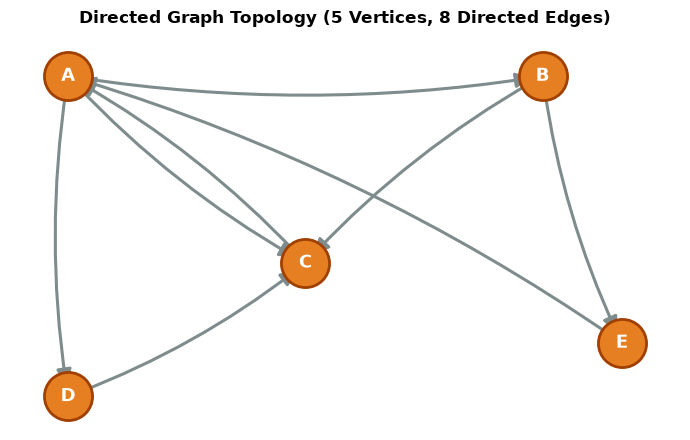

In [6]:
G_dir = nx.DiGraph()
G_dir.add_nodes_from(vertices)

edges_dir = [
    ("A", "B"),
    ("A", "C"),
    ("A", "D"),
    ("B", "C"),
    ("B", "E"),
    ("C", "A"),
    ("D", "C"),
    ("E", "A"),
]
G_dir.add_edges_from(edges_dir)

plt.figure(figsize=(7, 4.5), dpi=100)
nx.draw_networkx_nodes(
    G_dir, pos, node_color="#E67E22", node_size=1200, edgecolors="#A04000", linewidths=2
)
nx.draw_networkx_edges(
    G_dir,
    pos,
    width=2.2,
    edge_color="#7F8C8D",
    arrows=True,
    arrowsize=22,
    arrowstyle="-|>",
    connectionstyle="arc3,rad=0.08",
)
nx.draw_networkx_labels(
    G_dir, pos, font_size=13, font_weight="bold", font_color="white"
)

plt.title(
    "Directed Graph Topology (5 Vertices, 8 Directed Edges)",
    fontsize=12,
    pad=14,
    fontweight="bold",
)
plt.axis("off")
plt.tight_layout()
plt.show()

Visualisasi graf berarah memperlihatkan sirkulasi tautan web: simpul $A$ menyebarkan
banyak tautan keluar (*hub authority*), simpul $C$ mengumpulkan banyak tautan masuk,
dan busur $E \to A$ memastikan jaringan tidak memiliki simpul buntu (*dead-end sink node*),
sehingga seluruh simpul dapat saling menjangkau secara sirkular.

## Directed Adjacency

Pada graf berarah, **Matriks Ketetanggaan (*Adjacency Matrix*)** $A_{ij}$ bersifat asimetris:
$$A_{ij} = \begin{cases} 1 & \text{jika terdapat busur dari } i \to j \\ 0 & \text{lainnya} \end{cases}$$
Jumlah entri pada **baris $i$** mencerminkan **Out-Degree**, sedangkan jumlah entri
pada **kolom $j$** mencerminkan **In-Degree**.

In [7]:
adj_dir_matrix = nx.to_numpy_array(G_dir, nodelist=vertices, dtype=int)
adj_dir_df = pd.DataFrame(adj_dir_matrix, index=vertices, columns=vertices)
adj_dir_df.index.name = "Simpul Asal (i)"
adj_dir_df.columns.name = "Simpul Tujuan (j)"
adj_dir_df

Simpul Tujuan (j),A,B,C,D,E
Simpul Asal (i),,,,,
A,0,1,1,1,0
B,0,0,1,0,1
C,1,0,0,0,0
D,0,0,1,0,0
E,1,0,0,0,0


Matriks adjasensi graf berarah bersifat asimetris ($A \neq A^T$). Misalnya, $A_{A \to B} = 1$
tetapi $A_{B \to A} = 0$, yang mengonfirmasi bahwa navigasi langsung hanya dimungkinkan
dari simpul $A$ ke simpul $B$.

## Directed Metrics

Pada graf berarah, derajat dipisahkan menjadi tiga komponen:
1. **In-Degree ($k_{\text{in}}$)**: Jumlah busur masuk (prestise / popularitas sitasi).
2. **Out-Degree ($k_{\text{out}}$)**: Jumlah busur keluar (aktivitas perujukan / hub).
3. **Total Degree ($k_{\text{total}}$)**: Jumlah total keterlibatan busur ($k_{\text{in}} + k_{\text{out}}$).
4. **Directed Clustering Coefficient**: Kerapatan segitiga berarah berdasarkan formulasi Fagiolo (2007).

In [8]:
in_deg = dict(G_dir.in_degree())
out_deg = dict(G_dir.out_degree())
clustering_dir = nx.clustering(G_dir)

metrics_dir = []
for node in vertices:
    in_nodes = sorted([u for u, v in G_dir.in_edges(node)])
    out_nodes = sorted([v for u, v in G_dir.out_edges(node)])
    metrics_dir.append(
        {
            "Simpul": node,
            "In-Degree": in_deg[node],
            "Out-Degree": out_deg[node],
            "Total Degree": in_deg[node] + out_deg[node],
            "Rujukan Masuk (In)": ", ".join(in_nodes) if in_nodes else "-",
            "Rujukan Keluar (Out)": ", ".join(out_nodes) if out_nodes else "-",
            "Directed Clustering": round(clustering_dir[node], 4),
        }
    )

dir_metrics_df = pd.DataFrame(metrics_dir).set_index("Simpul")
dir_metrics_df

,In-Degree,Out-Degree,Total Degree,Rujukan Masuk (In),Rujukan Keluar (Out),Directed Clustering
Simpul,,,,,,
A,2,3,5,"C, E","B, C, D",0.2778
B,1,2,3,A,"C, E",0.5000
C,3,1,4,"A, B, D",A,0.4000
D,1,1,2,A,C,1.0000
E,1,1,2,B,A,0.5000


Hasil analisis metrik berarah mendemonstrasikan dinamika peranan:
- **Simpul $C$** memiliki **In-Degree tertinggi (3)**, bertindak sebagai *authority node* (halaman yang paling banyak dirujuk).
- **Simpul $A$** memiliki **Out-Degree tertinggi (3)**, bertindak sebagai *hub directory* (halaman indeks referensi).
- **Simpul $D$** memiliki *Directed Clustering* maksimal (**1,0000**) karena siklus tautan antara $D \to C \to A \to D$ membentuk pola transitif berarah sempurna.

## Directed Distribution

Distribusi derajat graf berarah dipisahkan menjadi distribusi busur masuk
(*In-Degree Distribution*, $P(k_{\text{in}})$) dan busur keluar
(*Out-Degree Distribution*, $P(k_{\text{out}})$).

In [9]:
in_counts = pd.Series(in_deg).value_counts().sort_index()
out_counts = pd.Series(out_deg).value_counts().sort_index()

all_k = sorted(set(in_counts.index).union(set(out_counts.index)))
dist_dir_list = []
for k in all_k:
    n_in = in_counts.get(k, 0)
    n_out = out_counts.get(k, 0)
    p_in = n_in / total_nodes
    p_out = n_out / total_nodes
    nodes_in = [n for n, d in in_deg.items() if d == k]
    nodes_out = [n for n, d in out_deg.items() if d == k]
    dist_dir_list.append(
        {
            "Derajat (k)": k,
            "Frekuensi In (N_in)": n_in,
            "P(k_in)": round(p_in, 2),
            "Simpul In": ", ".join(nodes_in) if nodes_in else "-",
            "Frekuensi Out (N_out)": n_out,
            "P(k_out)": round(p_out, 2),
            "Simpul Out": ", ".join(nodes_out) if nodes_out else "-",
        }
    )

dist_dir_df = pd.DataFrame(dist_dir_list).set_index("Derajat (k)")
dist_dir_df

,Frekuensi In (N_in),P(k_in),Simpul In,Frekuensi Out (N_out),P(k_out),Simpul Out
Derajat (k),,,,,,
1,3,0.6,"B, D, E",3,0.6,"C, D, E"
2,1,0.2,A,1,0.2,B
3,1,0.2,C,1,0.2,A


Distribusi memperlihatkan bahwa 60% simpul memiliki $k_{\text{in}} = 1$, sementara
hanya 20% simpul yang memiliki $k_{\text{in}} = 2$ dan $k_{\text{in}} = 3$. Pola serupa
teramati pada derajat keluar di mana simpul dengan out-degree 1 mendominasi (40%).

## Directed Macro

Karakteristik global graf berarah mencakup:
1. **Rata-rata Derajat Masuk & Keluar**: $\langle k_{\text{in}} \rangle = \langle k_{\text{out}} \rangle = \frac{E}{N}$.
2. **Kepadatan Graf Berarah**: $\rho_{\text{dir}} = \frac{E}{N(N-1)}$.
3. **Rata-rata Koefisien Kluster Berarah**: $\langle C_{\text{dir}} \rangle = \frac{1}{N} \sum C_i^{\text{dir}}$.
4. **Diameter Graf Berarah**: Panjang lintasan berarah terpanjang antar dua simpul.
5. **Rata-rata Lintasan Terpendek Berarah**: Jarak lintasan berarah terpendek antar seluruh pasangan simpul terurut.

In [10]:
avg_in = sum(in_deg.values()) / len(vertices)
avg_out = sum(out_deg.values()) / len(vertices)
density_dir = nx.density(G_dir)
is_strongly = nx.is_strongly_connected(G_dir)
avg_clust_dir = nx.average_clustering(G_dir)
diameter_dir = nx.diameter(G_dir) if is_strongly else float("nan")
avg_path_dir = nx.average_shortest_path_length(G_dir) if is_strongly else float("nan")

macro_dir_df = pd.DataFrame(
    [
        {
            "Metrik Makro": "Jumlah Simpul (N)",
            "Nilai": len(vertices),
            "Keterangan": "Total vertex jaringan berarah",
        },
        {
            "Metrik Makro": "Jumlah Busur (E)",
            "Nilai": G_dir.number_of_edges(),
            "Keterangan": "Total directed edges",
        },
        {
            "Metrik Makro": "Rata-rata In-Degree",
            "Nilai": round(avg_in, 4),
            "Keterangan": "<k_in> = E / N",
        },
        {
            "Metrik Makro": "Rata-rata Out-Degree",
            "Nilai": round(avg_out, 4),
            "Keterangan": "<k_out> = E / N",
        },
        {
            "Metrik Makro": "Kepadatan Graf (Density)",
            "Nilai": round(density_dir, 4),
            "Keterangan": "8 busur dari 20 busur maksimal (40%)",
        },
        {
            "Metrik Makro": "Rata-rata Koefisien Kluster (<C>)",
            "Nilai": round(avg_clust_dir, 4),
            "Keterangan": "Rata-rata kluster berarah Fagiolo",
        },
        {
            "Metrik Makro": "Terkoneksi Kuat (Strongly Connected)",
            "Nilai": str(is_strongly),
            "Keterangan": "Seluruh simpul dapat saling menjangkau",
        },
        {
            "Metrik Makro": "Diameter Graf Berarah",
            "Nilai": diameter_dir,
            "Keterangan": "Jarak lintasan berarah terjauh (B ke D)",
        },
        {
            "Metrik Makro": "Rata-rata Lintasan Terpendek",
            "Nilai": round(avg_path_dir, 4),
            "Keterangan": "Rata-rata langkah navigasi berarah",
        },
    ]
).set_index("Metrik Makro")
macro_dir_df

,Nilai,Keterangan
Metrik Makro,,
Jumlah Simpul (N),5,Total vertex jaringan berarah
Jumlah Busur (E),8,Total directed edges
Rata-rata In-Degree,1.6,<k_in> = E / N
Rata-rata Out-Degree,1.6,<k_out> = E / N
Kepadatan Graf (Density),0.4,8 busur dari 20 busur maksimal (40%)
Rata-rata Koefisien Kluster (<C>),0.5356,Rata-rata kluster berarah Fagiolo
Terkoneksi Kuat (Strongly Connected),True,Seluruh simpul dapat saling menjangkau
Diameter Graf Berarah,4,Jarak lintasan berarah terjauh (B ke D)
Rata-rata Lintasan Terpendek,1.85,Rata-rata langkah navigasi berarah


Kepadatan graf berarah bernilai **0,4000** (8 busur dari kapasitas maksimal 20 busur).
Karena jaringan berarah terbukti terkoneksi kuat (*strongly connected*), rata-rata panjang
lintasan terpendek dapat dihitung secara valid pada seluruh 20 pasangan simpul, yaitu
**1,8500 langkah**, dengan **diameter 4 langkah** (jarak terpendek dari simpul $B$ ke $D$ melalui $B \to E \to A \to D$).
Koefisien kluster rata-rata global bernilai **0,5356**.

## Metric Comparison

Perbandingan langsung seluruh metrik simpul antara model tidak berarah dan berarah.

In [11]:
comparison_df = pd.DataFrame(
    {
        "Undir Degree": undir_metrics_df["Degree (k_i)"],
        "Undir Clustering": undir_metrics_df["Clustering Coefficient"],
        "Dir In-Degree": dir_metrics_df["In-Degree"],
        "Dir Out-Degree": dir_metrics_df["Out-Degree"],
        "Dir Total Degree": dir_metrics_df["Total Degree"],
        "Dir Clustering": dir_metrics_df["Directed Clustering"],
    },
    index=vertices,
)
comparison_df.index.name = "Simpul"
comparison_df

,Undir Degree,Undir Clustering,Dir In-Degree,Dir Out-Degree,Dir Total Degree,Dir Clustering
Simpul,,,,,,
A,3,0.6667,2,3,5,0.2778
B,3,0.3333,1,2,3,0.5000
C,3,0.6667,3,1,4,0.4000
D,2,1.0000,1,1,2,1.0000
E,1,0.0000,1,1,2,0.5000


Tabel komparasi membuktikan bahwa memperhitungkan arah sisi (*directionality*) memberikan resolusi
asimetris yang sangat esensial:
- Simpul $A, B, C$ yang identik berderajat 3 pada graf tidak berarah terdiferensiasi secara tajam pada graf berarah: $A$ menjadi penyedia tautan utama ($k_{\text{out}}=3$), sedangkan $C$ menjadi penampung sitasi utama ($k_{\text{in}}=3$).
- Koefisien kluster berarah mengecil ($0,4000$ vs $0,6667$) karena segitiga yang terbentuk harus memenuhi orientasi arah yang konsisten agar dapat dilalui.

## Graph Characterization

Karakterisasi graf merangkum profil topologis komparatif jaringan berdasarkan sintesis
seluruh metrik yang telah diekstraksi.

In [12]:
char_data = [
    {
        "Dimensi Karakteristik": "Tipe Konektivitas Global",
        "Graf Tidak Berarah": "Connected Graph (1 komponen)",
        "Graf Berarah": "Strongly Connected (sirkular)",
        "Dampak Topologis": "Seluruh simpul dapat saling bertukar informasi",
    },
    {
        "Dimensi Karakteristik": "Kerapatan Jaringan (Density)",
        "Graf Tidak Berarah": f"{density_undir:.4f} (Relatif Padat)",
        "Graf Berarah": f"{density_dir:.4f} (Moderat)",
        "Dampak Topologis": "60% sisi dan 40% busur dari batas maksimal terisi",
    },
    {
        "Dimensi Karakteristik": "Koefisien Kluster Rata-rata (<C>)",
        "Graf Tidak Berarah": f"{avg_clust_undir:.4f}",
        "Graf Berarah": f"{avg_clust_dir:.4f}",
        "Dampak Topologis": "Kecenderungan pembentukan kluster lokal tinggi (> 0.5)",
    },
    {
        "Dimensi Karakteristik": "Jarak Efektif (Diameter & Lintasan)",
        "Graf Tidak Berarah": f"Diameter = {diameter_undir}, Rata-rata = {avg_path_undir:.4f}",
        "Graf Berarah": f"Diameter = {diameter_dir}, Rata-rata = {avg_path_dir:.4f}",
        "Dampak Topologis": "Sifat Small-World: diameter pendek dengan kluster tinggi",
    },
    {
        "Dimensi Karakteristik": "Struktur Hirarki Simpul",
        "Graf Tidak Berarah": "Core-Periphery (Core: A,B,C; Periphery: E)",
        "Graf Berarah": "Hub-Authority (Authority: C; Hub: A)",
        "Dampak Topologis": "Meniru topologi web realistis (fondasi PageRank/HITS)",
    },
]
char_df = pd.DataFrame(char_data).set_index("Dimensi Karakteristik")
char_df

,Graf Tidak Berarah,Graf Berarah,Dampak Topologis
Dimensi Karakteristik,,,
Tipe Konektivitas Global,Connected Graph (1 komponen),Strongly Connected (sirkular),Seluruh simpul dapat saling bertukar informasi
Kerapatan Jaringan (Density),0.6000 (Relatif Padat),0.4000 (Moderat),60% sisi dan 40% busur dari batas maksimal terisi
Koefisien Kluster Rata-rata (<C>),0.5333,0.5356,Kecenderungan pembentukan kluster lokal tinggi...
Jarak Efektif (Diameter & Lintasan),"Diameter = 3, Rata-rata = 1.5000","Diameter = 4, Rata-rata = 1.8500",Sifat Small-World: diameter pendek dengan klus...
Struktur Hirarki Simpul,"Core-Periphery (Core: A,B,C; Periphery: E)",Hub-Authority (Authority: C; Hub: A),Meniru topologi web realistis (fondasi PageRan...


Sintesis karakterisasi graf mengungkap tiga sifat fundamental jaringan:
1. **Efek Dunia Kecil (*Small-World Phenomenon*)**: Jaringan memiliki koefisien kluster rata-rata yang relatif tinggi ($\langle C \rangle > 0,53$) dipadukan dengan jarak rata-rata yang pendek ($L \le 1,85$ langkah dan diameter $\le 4$), mencerminkan keterhubungan cepat antarhalaman web.
2. **Struktur Inti-Tepi (*Core-Periphery*)**: Pada model tidak berarah, simpul $A, B, C$ menjadi inti (*core*), sedangkan simpul $E$ adalah tepi (*periphery*).
3. **Polarisasi Otoritas-Hub (*Authority-Hub Polarization*)**: Pada model berarah, orientasi busur menciptakan spesialisasi peran: simpul $C$ sebagai penampung otoritas sitasi (*inbound authority*) dan simpul $A$ sebagai penyedia direktori rujukan (*outbound hub*).

## Conclusion

Eksperimen penambangan graf dengan 5 simpul menggunakan pustaka `networkx` berhasil
menuntaskan seluruh aspek analisis topologi jaringan web:
1. **Representasi Topologi**: Graf tidak berarah (6 sisi simetris) dan graf berarah (8 busur asimetris) berhasil dimodelkan dan divisualisasikan secara komparatif.
2. **Matriks Ketetanggaan (*Adjacency Matrix*)**: Pembuktian sifat simetri matriks pada graf tidak berarah ($A_{ij} = A_{ji}$) berbanding asimetri pada graf berarah ($A_{ij} \neq A_{ji}$), di mana jumlahan baris memetakan *out-degree* dan jumlahan kolom memetakan *in-degree*.
3. **Analisis Derajat & Distribusi**: Derajat simpul dihitung per simpul beserta distribusi frekuensi $P(k)$ dan rata-rata derajat jaringan ($\langle k \rangle = 2,4000$ pada tidak berarah; $\langle k_{\text{in}} \rangle = \langle k_{\text{out}} \rangle = 1,6000$ pada berarah).
4. **Metrik Makro (Density, Diameter, & Path Length)**: Kepadatan graf diukur pada 0,6000 (tidak berarah) dan 0,4000 (berarah); diameter diukur pada 3 langkah (tidak berarah) dan 4 langkah (berarah); serta rata-rata lintasan terpendek diukur pada 1,5000 langkah (tidak berarah) dan 1,8500 langkah (berarah).
5. **Koefisien Kluster**: Simpul $D$ mencapai koefisien kluster tertinggi (1,0000) pada kedua varian graf, dengan koefisien kluster rata-rata global $\langle C \rangle = 0,5333$ (tidak berarah) dan $0,5356$ (berarah).
6. **Karakterisasi Graf**: Jaringan terbukti memiliki karakteristik *small-world*, struktur *core-periphery*, dan hierarki *hub-authority* yang relevan untuk algoritma PageRank dan HITS.